# 02. 空間 × 群の作り方の横並びと、小さな部分集団

01 と同じ 1 段・ERM の Spatial LoRA（CheXpert race-known、seed 42・43・44）の予測について、潜在サブグループを
5 つの空間と 2 つの作り方で探し、同じ物差しで並べる。

| 空間 | クラスタリング | 見落としの監査器 |
|---|---|---|
| 属性（one-hot ＋ 年齢） | 基準：8 群（年齢 65 歳 × race）、細かいセル（年齢 65 歳 × 性別 × race × 撮影の向き） | ridge・木 |
| metadata encoder の c | k-means（K = 8） | ridge・木 |
| 生成 ΔW（3 stage の和） | k-means（K = 8） | （c の関数なので省略） |
| モデル自身の特徴（head 直前） | GEORGE（クラスごとの GMM、K = 4 × 2 クラス）、LHCF（GMM、K は BIC） | ridge・木 |
| RAD-DINO（胸部 X 線の自己教師あり、ラベル不使用） | LHCF（GMM、K は BIC） | ridge・木 |

監査器は、val の陰性で「0.5 で所見なしと出したか（見落とし）」を入力から予測する。ridge は予測値の分位で 8 群、
木は葉を群にする（葉の最小件数 500）。群はすべて val で作り、test で測る。

後半では、クラスタリングでは拾えない小さな部分集団について、群を細かくしたとき・k 近傍の球で走査したときに、
val で見つけた偏りが test でも残るかを見る。

> **読むときの注意（実行後に追記）**：見落とし（しきい値 0.5 で所見なしと出したか）は得点の関数なので、得点を予測できる空間で見落としを目的に群を探すと、決定境界の「所見なし」側を切り出すだけになる。モデル自身の特徴では最悪群の FPR が 1.0（自明）、RAD-DINO でも 0.8 前後になる。これは「難しい陰性」の塊で、群に特有のずれとは区別できない。画像を見る空間の比較は、得点をそろえたうえでの O/E を測る [03](03_calibration_bias.ipynb) で読む。属性・c・ΔW は画像を見ないので、この問題は起きない。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rootutils
from IPython.display import display

ROOT = rootutils.setup_root(Path.cwd(), indicator=".project-root", pythonpath=True)
from analysis.common.paths import STYLE_SHEET, study_dir  # noqa: E402
from analysis.latent_subgroup_spaces import subgroups as sg  # noqa: E402

plt.style.use(STYLE_SHEET)
PACKAGE = study_dir("latent_subgroup_spaces")
TOPIC = "02_space_comparison"
RESULTS = PACKAGE / "results" / TOPIC
FIGURES = PACKAGE / "figures" / TOPIC
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RUNS = {
    42: "20261002T125005Z-spatial-lora-chexpert-race-known-s42-a21c",
    43: "20261002T145233Z-spatial-lora-chexpert-race-known-s43-424e",
    44: "20261002T165551Z-spatial-lora-chexpert-race-known-s44-eb13",
}
CLUSTER_DIMS = 32   # クラスタリング前の PCA の次元（LHCF の実装と同じ）
AUDIT_DIMS = 64     # 監査器の入力の PCA の次元
K_CLUSTER = 8       # 評価の 8 群と同じ数
K_GEORGE = 4        # クラスあたりの部分クラス数（2 クラスで 8 群）
BIC_KS = range(2, 13)
RIDGE_BINS = 8
TREE_MIN_LEAF = 500
MAIN_DISEASES = ["dz_Pleural Effusion", "dz_Atelectasis", "dz_Lung Opacity", "dz_Cardiomegaly", "dz_Edema"]
STRATA = {
    "none": [],
    "attr8": ["age65", "race_group"],
    "inputs": ["age65", "sex", "race_group", "frontal_lateral", "ap_pa"],
    "context": [*MAIN_DISEASES, "device", "sternotomy", "report_type"],
    "inputs+context": ["age65", "sex", "race_group", "frontal_lateral", "ap_pa", *MAIN_DISEASES, "device", "sternotomy", "report_type"],
}

## 読み込みと空間

ΔW は 01 と同じく Gram の重み付き kernel PCA の座標。特徴と RAD-DINO は val で標準化と PCA を当てる。
属性は one-hot ＋ 年齢（監査器の入力）。細かいセルは `view`（AP・PA・側面）を足した 48 セル。

In [2]:
def delta_all(run_id, splits):
    cells, _, grams = sg.load_cells(run_id)
    coordinates = sg.kernel_coordinates(grams["stage3"] + grams["stage4"] + grams["fc"], cells.train_count.to_numpy() + 1e-3)
    return {split: coordinates[data.frame.cell.to_numpy()] for split, data in splits.items()}


def add_view(frame):
    view = np.where(frame.frontal_lateral == 1, 2, frame.ap_pa)  # 0 = AP、1 = PA、2 = 側面
    return frame.assign(view=view, fine48=((frame.age65 * 2 + frame.sex) * 4 + frame.race_group) * 3 + view)


DATA, SPACES = {}, {}
for seed, run_id in RUNS.items():
    splits = {split: sg.load_split(run_id, split) for split in ("val", "test")}
    for data in splits.values():
        data.frame = add_view(data.frame)
    val, test = splits["val"], splits["test"]
    feat32 = sg.reduce(val.features, test.features, CLUSTER_DIMS)
    feat64 = sg.reduce(val.features, test.features, AUDIT_DIMS)
    rad32 = sg.reduce(val.raddino, test.raddino, CLUSTER_DIMS)
    rad64 = sg.reduce(val.raddino, test.raddino, AUDIT_DIMS)
    attributes = sg.attribute_matrix(pd.concat([val.frame, test.frame]))
    DATA[seed] = splits
    SPACES[seed] = {
        "attributes": (attributes[: len(val.frame)], attributes[len(val.frame) :]),
        "c": (val.condition, test.condition),
        "dW": tuple(delta_all(run_id, splits).values()),
        "feat32": feat32,
        "feat64": feat64,
        "rad32": rad32,
        "rad64": rad64,
    }
print({name: values[0].shape for name, values in SPACES[42].items()})

{'attributes': (20058, 13), 'c': (20058, 16), 'dW': (20058, 19), 'feat32': (20058, 32), 'feat64': (20058, 64), 'rad32': (20058, 32), 'rad64': (20058, 64)}


## LHCF の K（BIC）

LHCF は GMM の K を BIC 最小で選ぶ。特徴と RAD-DINO の両方で、seed ごとに選ぶ。

In [3]:
bic_rows = []
for seed in RUNS:
    for space in ("feat32", "rad32"):
        table = sg.gmm_bic_k(SPACES[seed][space][0], BIC_KS)
        bic_rows.append(table.assign(seed=seed, space=space))
bic = pd.concat(bic_rows, ignore_index=True)
bic.to_csv(RESULTS / "lhcf_bic.csv", index=False)
LHCF_K = {(row.seed, row.space): int(row.k) for row in bic.loc[bic.groupby(["seed", "space"]).bic.idxmin()].itertuples()}
display(pd.Series(LHCF_K, name="bic_k"))

/home/akiba/workspace/hypernet-fairness/.venv/lib/python3.11/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


42  feat32    12
    rad32     11
43  feat32    12
    rad32     11
44  feat32    12
    rad32     11
Name: bic_k, dtype: int64

## 群を作る

`PARTITIONS[(seed, 名前)] = (val の群番号, test の群番号)`。名前は「空間 / 作り方」。

In [4]:
def build_partitions(seed):
    space = SPACES[seed]
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    out = {
        "attributes / 8 groups": (val.attr8.to_numpy(), test.attr8.to_numpy()),
        "attributes / 48 fine cells": (val.fine48.to_numpy(), test.fine48.to_numpy()),
        "c / k-means": sg.kmeans_groups(*space["c"], K_CLUSTER),
        "dW / k-means": sg.kmeans_groups(*space["dW"], K_CLUSTER),
        "feat / GEORGE": sg.george_groups(*space["feat32"], val.target.to_numpy(), test.target.to_numpy(), K_GEORGE),
        "feat / LHCF": sg.gmm_groups(*space["feat32"], LHCF_K[(seed, "feat32")]),
        "RAD-DINO / LHCF": sg.gmm_groups(*space["rad32"], LHCF_K[(seed, "rad32")]),
    }
    audit_inputs = {"attributes": space["attributes"], "c": space["c"], "feat": space["feat64"], "RAD-DINO": space["rad64"]}
    for name, (val_x, test_x) in audit_inputs.items():
        out[f"{name} / audit ridge"] = sg.miss_auditor(val_x, test_x, val, "ridge", RIDGE_BINS)[:2]
        out[f"{name} / audit tree"] = sg.miss_auditor(val_x, test_x, val, "tree", TREE_MIN_LEAF)[:2]
    return out


PARTITIONS = {(seed, name): groups for seed in RUNS for name, groups in build_partitions(seed).items()}
METHODS = list(dict.fromkeys(name for _, name in PARTITIONS))

## 1. 横並び：最悪群の FPR と、その中身

- `worst_fpr`・`excess_over_null`：test の最悪群の FPR と、同じ大きさのランダムな群の最悪値（平均）からの超過
- `val_chosen_test_fpr`：val で最悪だった群の test の FPR（勝者の呪いを除く）
- `nmi_attr8`・`nmi_inputs`：群が属性（8 群／モデル入力の属性のセル）でどれだけ決まるか
- `oe_*`：見落とし数の O/E の SD。層を入れたあとに残るばらつき（小さいほど、その層で群の違いが説明できる）

In [5]:
def oe_spread(test_groups, frame, strata):
    if not strata:
        frame, strata = frame.assign(_all=0), ["_all"]
    table = sg.standardized_excess(test_groups, frame, strata)
    table = table[table.n_neg >= sg.MIN_CELL]
    return float(np.sqrt(np.average((table.o_e - 1) ** 2, weights=table.n_neg)))


rows = []
for (seed, name), (val_groups, test_groups) in PARTITIONS.items():
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    row = sg.summarize_partition(name, val_groups, test_groups, val, test)
    row.update(
        seed=seed,
        nmi_attr8=sg.explained_by(test_groups, test, ["age65", "race_group"]),
        nmi_inputs=sg.explained_by(test_groups, test, ["age65", "sex", "race_group", "view"]),
        **{f"oe_{label}": oe_spread(test_groups, test, strata) for label, strata in STRATA.items()},
    )
    rows.append(row)
comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS / "comparison_by_seed.csv", index=False)
columns = [
    "groups_valid", "min_n_neg", "worst_fpr", "excess_over_null", "val_chosen_test_fpr", "val_chosen_n_neg",
    "fpr_sd", "prevalence_range", "nmi_attr8", "nmi_inputs", *[f"oe_{label}" for label in STRATA],
]
comparison_mean = comparison.groupby("partition", sort=False)[columns].mean().loc[METHODS]
comparison_mean.to_csv(RESULTS / "comparison_mean.csv")
display(comparison_mean.round(3))

,groups_valid,min_n_neg,worst_fpr,excess_over_null,val_chosen_test_fpr,val_chosen_n_neg,fpr_sd,prevalence_range,nmi_attr8,nmi_inputs,oe_none,oe_attr8,oe_inputs,oe_context,oe_inputs+context
partition,,,,,,,,,,,,,,,
attributes / 8 groups,8.000,303.000,0.363,0.099,0.322,766.000,0.074,0.114,1.000,0.699,0.311,0.000,0.000,0.244,0.000
attributes / 48 fine cells,44.000,44.000,0.571,0.225,0.516,119.333,0.120,0.263,0.699,1.000,0.501,0.369,0.000,0.281,0.000
c / k-means,8.000,1126.333,0.507,0.247,0.507,1183.000,0.111,0.229,0.308,0.500,0.469,0.334,0.128,0.263,0.070
dW / k-means,8.000,753.667,0.497,0.235,0.496,766.333,0.112,0.270,0.259,0.422,0.473,0.338,0.173,0.275,0.116
feat / GEORGE,4.000,2733.000,0.835,0.582,0.835,4615.333,0.353,0.000,0.015,0.129,1.452,1.371,1.198,0.864,0.769
feat / LHCF,12.000,797.000,0.999,0.733,0.999,1119.333,0.361,0.392,0.020,0.202,1.485,1.366,1.320,0.888,0.812
RAD-DINO / LHCF,11.000,37.000,0.580,0.294,0.580,1094.000,0.143,0.215,0.010,0.330,0.588,0.554,0.455,0.275,0.209
attributes / audit ridge,8.000,2058.333,0.502,0.243,0.502,2273.333,0.122,0.215,0.210,0.376,0.512,0.350,0.131,0.269,0.092
attributes / audit tree,25.333,415.000,0.536,0.256,0.533,839.667,0.127,0.258,0.307,0.581,0.529,0.393,0.220,0.305,0.149


### seed をまたいだ一致（test の ARI）

In [6]:
ari = pd.Series({name: sg.seed_agreement({seed: PARTITIONS[(seed, name)][1] for seed in RUNS}) for name in METHODS}, name="seed_ari")
ari.to_csv(RESULTS / "seed_ari.csv")
display(ari.round(2))

attributes / 8 groups         1.00
attributes / 48 fine cells    1.00
c / k-means                   0.45
dW / k-means                  0.47
feat / GEORGE                 0.45
feat / LHCF                   0.25
RAD-DINO / LHCF               1.00
attributes / audit ridge      0.61
attributes / audit tree       0.66
c / audit ridge               0.40
c / audit tree                0.32
feat / audit ridge            0.24
feat / audit tree             0.37
RAD-DINO / audit ridge        0.51
RAD-DINO / audit tree         0.44
Name: seed_ari, dtype: float64

## 2. val で最悪だった群の中身

各方式で val の FPR が最悪の群を選び、test の陰性での要因の割合を陰性全体と比べる（3 seed の比の平均）。
病種は CheXbert（impression）で陽性のもの、文脈は報告書の正規表現（デバイス・ペースメーカー・PICC・中心静脈・
胸骨切開・手術クリップ・追跡撮影・正常を明言するレポート）。`pa` は PA 撮影（外来の立位）、`lateral` は側面像。

In [7]:
FACTORS = [
    "young", "female", "black", "asian", "pa", "lateral", "affirmed_normal",
    *sg.CONTEXT_FLAGS, *[f"dz_{name}" for name in sg.DISEASES],
]


def with_factor_columns(frame):
    return frame.assign(
        young=frame.age65 == 0,
        female=frame.sex == 1,
        black=frame.race_group == 3,
        asian=frame.race_group == 2,
        pa=frame.view == 1,
        lateral=frame.view == 2,
        affirmed_normal=frame.report_type == "affirmed_normal",
    )


enrich_rows, chosen_rows = [], []
for (seed, name), (val_groups, test_groups) in PARTITIONS.items():
    val_table = sg.group_table(val_groups, DATA[seed]["val"].frame)
    chosen = val_table.loc[val_table.fpr.idxmax(), "group"]
    frame = with_factor_columns(DATA[seed]["test"].frame)
    enrich_rows.append(sg.enrichment(test_groups == chosen, frame, FACTORS).assign(seed=seed, partition=name))
enrich = pd.concat(enrich_rows, ignore_index=True)
enrich.to_csv(RESULTS / "worst_group_enrichment.csv", index=False)
enrich_mean = enrich.pivot_table(index="factor", columns="partition", values="ratio", aggfunc="mean")[METHODS].loc[FACTORS]
display(enrich_mean.round(2))

partition,attributes / 8 groups,attributes / 48 fine cells,c / k-means,dW / k-means,feat / GEORGE,feat / LHCF,RAD-DINO / LHCF,attributes / audit ridge,attributes / audit tree,c / audit ridge,c / audit tree,feat / audit ridge,feat / audit tree,RAD-DINO / audit ridge,RAD-DINO / audit tree
factor,,,,,,,,,,,,,,,
young,1.92,1.92,1.74,1.92,1.16,1.47,1.19,1.85,1.92,1.86,1.92,1.49,1.36,1.44,1.39
female,1.10,2.42,1.13,1.57,1.03,0.90,0.85,1.07,0.93,1.04,0.64,1.03,1.04,0.89,0.99
black,0.00,0.00,1.29,2.01,1.05,1.04,1.02,1.17,1.38,1.13,0.70,1.12,1.06,1.11,1.26
asian,16.44,10.96,1.34,1.86,1.04,1.13,0.92,1.58,1.64,1.57,1.25,1.21,1.15,1.09,1.66
pa,1.17,5.45,4.89,2.99,1.72,3.56,0.00,4.40,2.73,4.14,6.48,1.99,1.76,2.18,5.10
lateral,1.19,2.43,2.40,3.05,1.58,1.04,7.30,3.11,4.87,3.33,1.35,1.73,1.69,2.03,0.29
affirmed_normal,1.39,2.20,2.31,2.32,2.60,3.89,2.84,2.36,2.49,2.37,2.43,3.55,3.15,3.73,3.58
followup,1.08,1.09,1.02,1.02,0.81,0.77,1.04,1.04,1.05,1.04,1.01,0.76,0.78,0.76,0.77
device,0.95,0.70,0.71,0.81,0.76,0.64,0.55,0.68,0.66,0.68,0.64,0.73,0.75,0.61,0.46


## 3. 小さな部分集団：群を細かくしたとき

クラスタの K と、木の葉の最小件数を振る。群が小さくなるほど、val で最悪の群は偶然で悪く見えやすい。
val で選んだ最悪群の **test** の FPR が全体の FPR を上回り続けるかで、「小さいが本物の偏り」が取れているかを見る。

In [8]:
CLUSTER_SWEEP = [8, 16, 32, 64, 128]
LEAF_SWEEP = [1000, 300, 100, 50, 25]
sweep_rows = []
for seed in RUNS:
    space = SPACES[seed]
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    candidates = {}
    for name, key in (("c", "c"), ("dW", "dW"), ("feat", "feat32"), ("RAD-DINO", "rad32")):
        for k in CLUSTER_SWEEP:
            candidates[(f"{name} / k-means", k)] = sg.kmeans_groups(*space[key], k)
    for name, key in (("attributes", "attributes"), ("c", "c"), ("feat", "feat64"), ("RAD-DINO", "rad64")):
        for leaf in LEAF_SWEEP:
            candidates[(f"{name} / audit tree", leaf)] = sg.miss_auditor(*space[key], val, "tree", leaf)[:2]
    for (name, size), (val_groups, test_groups) in candidates.items():
        row = sg.summarize_partition(name, val_groups, test_groups, val, test, null_draws=100)
        val_table = sg.group_table(val_groups, val)
        row.update(seed=seed, setting=size, val_chosen_val_fpr=val_table.fpr.max())
        sweep_rows.append(row)
sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(RESULTS / "granularity_sweep.csv", index=False)
sweep_mean = sweep.groupby(["partition", "setting"], sort=False)[
    ["groups_valid", "val_chosen_n_neg", "val_chosen_val_fpr", "val_chosen_test_fpr", "overall_fpr", "worst_fpr", "null_worst_p95"]
].mean()
display(sweep_mean.round(3))

groups_valid  val_chosen_n_neg  \
partition               setting                                   
c / k-means             8               8.000          1183.000   
                        16             16.000           671.667   
                        32             32.000           217.333   
                        64             64.000           113.000   
                        128           120.000            28.667   
dW / k-means            8               8.000           766.333   
                        16             16.000           293.667   
                        32             32.000           161.333   
                        64             63.000            49.667   
                        128           117.667            27.333   
feat / k-means          8               8.000          1724.333   
                        16             16.000           994.000   
                        32             32.000           647.333   
                        64             63.333           413.667   
                        128           125.333           148.000   
RAD-DINO / k-means      8               8.000           419.000   
                        16             16.000           637.333   
                        32             31.000           360.000   
                        64             62.000            66.000   
                        128           124.000            62.000   
attributes / audit tree 1000           13.333          1364.333   
                        300            43.667           418.333   
                        100           118.333           113.000   
                        50            212.333            39.000   
                        25            311.000            22.667   
c / audit tree          1000           14.000          1387.000   
                        300            45.667           382.000   
                        100           126.667           141.667   
                        50            224.333            64.000   
                        25            319.667            25.000   
feat / audit tree       1000            8.000          2724.000   
                        300            16.000          3094.000   
                        100            28.667          3297.667   
                        50             40.000            77.000   
                        25             52.000            70.667   
RAD-DINO / audit tree   1000           13.333          1225.000   
                        300            43.000           361.000   
                        100           119.000           135.333   
                        50            207.000           105.000   
                        25            321.000            82.333   

                                 val_chosen_val_fpr  val_chosen_test_fpr  \
partition               setting                                            
c / k-means             8                     0.517                0.507   
                        16                    0.548                0.537   
                        32                    0.595                0.529   
                        64                    0.618                0.556   
                        128                   0.714                0.579   
dW / k-means            8                     0.515                0.496   
                        16                    0.576                0.525   
                        32                    0.595                0.588   
                        64                    0.690                0.611   
                        128                   0.730                0.577   
feat / k-means          8                     0.999                0.999   
                        16                    1.000                1.000   
                        32                    1.000                1.000   
                        64                    1.000                1.000   
  

/tmp/ipykernel_2510187/4127226718.py:15: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


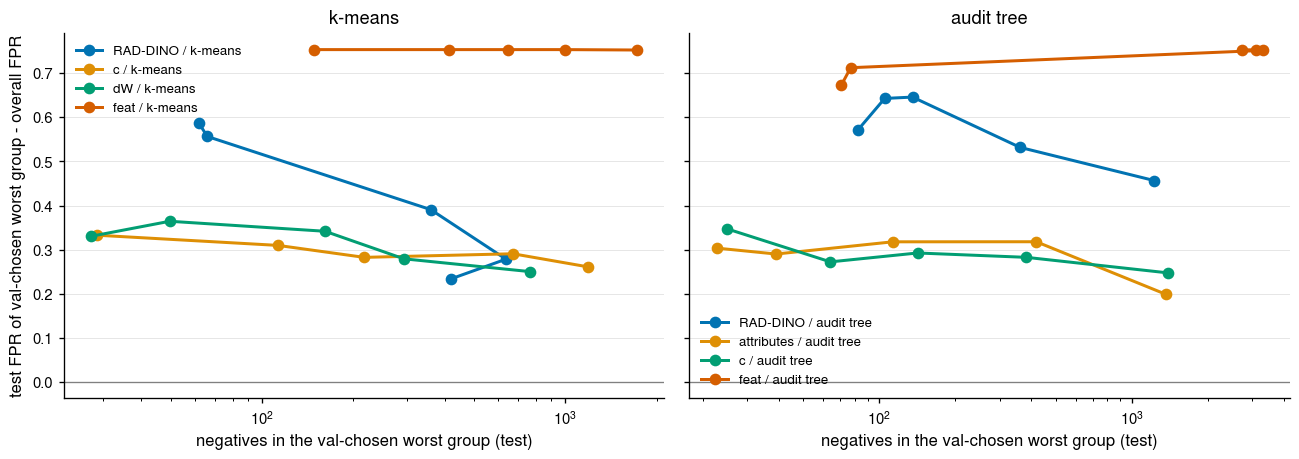

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, family in zip(axes, ("k-means", "audit tree")):
    part = sweep[sweep.partition.str.endswith(family)]
    for name, rows in part.groupby("partition"):
        mean = rows.groupby("setting")[["val_chosen_n_neg", "val_chosen_test_fpr", "overall_fpr"]].mean()
        excess = mean.val_chosen_test_fpr - mean.overall_fpr
        axis.plot(mean.val_chosen_n_neg, excess, marker="o", label=name)
    axis.set_xscale("log")
    axis.axhline(0, color="gray", lw=0.8)
    axis.set_xlabel("negatives in the val-chosen worst group (test)")
    axis.set_title(family)
axes[0].set_ylabel("test FPR of val-chosen worst group - overall FPR")
for axis in axes:
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "granularity_sweep.png", dpi=150)
plt.show()

## 4. 小さな部分集団：k 近傍の球の走査

val の陰性を中心に k 近傍の球を作り、見落としが最も集中する球を二項の尤度比で選ぶ（走査統計）。
並べ替えた帰無分布で p 値を出し、選んだ球の半径を test にそのまま当てて FPR を測る。
クラスタの境界に縛られず、k 件の大きさの局所を直接探す。空間は特徴と RAD-DINO（PCA 32 次元）。

In [10]:
SCAN_KS = [25, 50, 100, 200, 500]
scan_rows, BALLS = [], {}
for seed in RUNS:
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    for name, key in (("feat", "feat32"), ("RAD-DINO", "rad32")):
        for k in SCAN_KS:
            result = sg.knn_scan(*SPACES[seed][key], val, test, k)
            BALLS[(seed, name, k)] = result
            scan_rows.append({key_: value for key_, value in result.items() if not key_.startswith("ball_rows")} | {"seed": seed, "space": name})
scan = pd.DataFrame(scan_rows)
scan.to_csv(RESULTS / "knn_scan.csv", index=False)
display(scan.groupby(["space", "k"])[["val_fpr_in_ball", "val_overall_fpr", "p_value", "test_n_neg_in_ball", "test_fpr_in_ball"]].mean().round(3))

val_fpr_in_ball  val_overall_fpr  p_value  test_n_neg_in_ball  \
space    k                                                                    
RAD-DINO 25             1.000            0.241     0.01              28.000   
         50             0.987            0.241     0.01              56.667   
         100            0.927            0.241     0.01             106.667   
         200            0.877            0.241     0.01             189.333   
         500            0.733            0.241     0.01             502.000   
feat     25             1.000            0.241     0.01              34.667   
         50             1.000            0.241     0.01              69.000   
         100            1.000            0.241     0.01             124.667   
         200            1.000            0.241     0.01             220.667   
         500            1.000            0.241     0.01             517.000   

              test_fpr_in_ball  
space    k                      
RAD-DINO 25              0.870  
         50              0.837  
         100             0.792  
         200             0.793  
         500             0.712  
feat     25              1.000  
         50              1.000  
         100             1.000  
         200             1.000  
         500             1.000

### 走査で見つけた球の中身

seed ごと・空間ごとに k = 100 の球（val の陰性）の要因の割合を、val の陰性全体と比べる。

In [11]:
ball_rows = []
for (seed, name, k), result in BALLS.items():
    if k != 100:
        continue
    frame = with_factor_columns(DATA[seed]["val"].frame)
    mask = np.zeros(len(frame), dtype=bool)
    mask[result["ball_rows_val"]] = True
    ball_rows.append(sg.enrichment(mask, frame, FACTORS).assign(seed=seed, space=name))
balls = pd.concat(ball_rows, ignore_index=True)
balls.to_csv(RESULTS / "knn_ball_enrichment_k100.csv", index=False)
display(balls.pivot_table(index="factor", columns=["space", "seed"], values="share_in_group").loc[FACTORS].round(2))
display(balls.groupby("factor").share_overall.mean().loc[FACTORS].round(2).rename("share_overall"))

space                         RAD-DINO              feat            
seed                                42    43    44    42    43    44
factor                                                              
young                             0.73  0.74  0.72  0.94  0.92  0.74
female                            0.02  0.27  0.00  0.65  0.52  0.55
black                             0.22  0.25  0.23  0.26  0.23  0.12
asian                             0.02  0.04  0.05  0.11  0.07  0.09
pa                                0.00  0.00  0.00  0.14  0.54  0.53
lateral                           1.00  1.00  1.00  0.00  0.00  0.04
affirmed_normal                   0.25  0.27  0.25  0.23  0.19  0.27
followup                          0.74  0.80  0.78  0.37  0.62  0.52
device                            0.36  0.41  0.35  0.45  0.43  0.35
pacer                             0.00  0.00  0.01  0.05  0.01  0.06
picc                              0.10  0.06  0.04  0.12  0.11  0.06
central_line                      0.21  0.22  0.18  0.21  0.17  0.12
sternotomy                        0.03  0.05  0.06  0.06  0.02  0.09
surgical_clip                     0.04  0.08  0.06  0.04  0.06  0.09
dz_Enlarged Cardiomediastinum     0.03  0.03  0.05  0.05  0.07  0.07
dz_Cardiomegaly                   0.02  0.07  0.04  0.11  0.05  0.13
dz_Lung Opacity                   0.27  0.26  0.28  0.24  0.34  0.22
dz_Lung Lesion                    0.08  0.12  0.09  0.07  0.03  0.07
dz_Edema                          0.01  0.01  0.01  0.17  0.11  0.05
dz_Consolidation                  0.02  0.03  0.01  0.00  0.02  0.02
dz_Pneumonia                      0.01  0.02  0.02  0.00  0.02  0.00
dz_Atelectasis                    0.02  0.05  0.04  0.14  0.18  0.11
dz_Pneumothorax                   0.01  0.01  0.01  0.04  0.04  0.01
dz_Pleural Effusion               0.10  0.09  0.13  0.05  0.06  0.05
dz_Pleural Other                  0.03  0.10  0.06  0.04  0.02  0.05
dz_Fracture                       0.07  0.07  0.07  0.03  0.07  0.05
dz_Support Devices                0.29  0.32  0.27  0.39  0.34  0.23

factor
young                            0.53
female                           0.40
black                            0.17
asian                            0.06
pa                               0.12
lateral                          0.14
affirmed_normal                  0.07
followup                         0.73
device                           0.59
pacer                            0.08
picc                             0.12
central_line                     0.23
sternotomy                       0.12
surgical_clip                    0.06
dz_Enlarged Cardiomediastinum    0.04
dz_Cardiomegaly                  0.16
dz_Lung Opacity                  0.52
dz_Lung Lesion                   0.04
dz_Edema                         0.25
dz_Consolidation                 0.07
dz_Pneumonia                     0.02
dz_Atelectasis                   0.16
dz_Pneumothorax                  0.09
dz_Pleural Effusion              0.46
dz_Pleural Other                 0.02
dz_Fracture                      0.04
dz_Su

## まとめ

観察と解釈は [reports/space_comparison.md](reports/space_comparison.md) に 03 とあわせて書く。